In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.optimize as scp

In [ ]:
def rate(t):
  return 12 + 8*np.cos(math.pi*(t-16)/12)

In [ ]:
#simulating process by uniform gams and sorting them
Nmax = np.random.poisson(20*720)
Tprop = np.random.rand(Nmax)*720
Tprop = np.sort(Tprop)
thresholds = rate(Tprop)/20
test = np.random.rand(Nmax)
Taccepted = np.where(test < thresholds, Tprop, 0)
acceptanceFrac = np.count_nonzero(Taccepted)/Nmax
Taccepted = Taccepted[Taccepted != 0]
print("Fraction accepted = " + str(round(acceptanceFrac, 4)))


Fraction accepted = 0.5895


In [ ]:
N = np.bincount(Taccepted.astype(int))
Ntot = np.sum(N)

Nbyday = np.reshape(N, (30,24))
Nbyhour = np.transpose(Nbyday)
avgArrivals = np.mean(Nbyhour, axis=1)

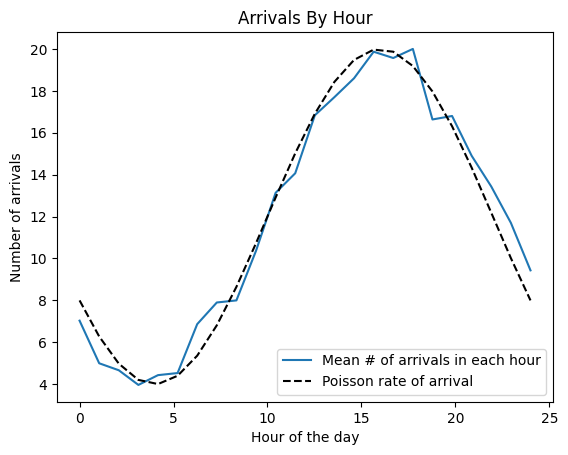

In [ ]:
fig, ax = plt.subplots()
day = np.linspace(0, 24, 24)
ax.plot(day, avgArrivals, label="Mean # of arrivals in each hour")
rates = rate(day)
ax.plot(day, rates, 'k--', label="Poisson rate of arrival")
ax.set_xlabel("Hour of the day")
ax.set_ylabel("Number of arrivals")
ax.legend()
ax.set_title("Arrivals By Hour")
plt.show()

In [ ]:
mean34 = avgArrivals[3]
var34 = np.var(Nbyhour[3])
print("Arrivals between 3 and 4 AM have mean " + str(round(mean34, 4)) + " and variance " + str(round(var34, 4)))

Arrivals between 3 and 4 AM have mean 3.9667 and variance 5.7656


In [ ]:
def negloglikelihood(params):
  a, b, phi = paramsD
  return -(np.sum(np.log(a+b*np.cos(math.pi*(Taccepted-phi)/12))) - a*720)

minimizers = scp.minimize(negloglikelihood, [10,5,14])
print("a, b, and phi were found to be " + str(minimizers["x"]) + ", respectively")


a, b, and phi were found to be [11.89305537  7.74201702 16.01873042], respectively


In [ ]:
loglikelihood = -negloglikelihood(minimizers["x"])
print("The log-likelihood was " + str(round(loglikelihood, 4)))
print("Total number of arrivals = " + str(Ntot))
constloglikelihood = Ntot*np.log(Ntot/720) - Ntot
print("The log-likelihood for constant rate was " + str(round(constloglikelihood, 4)))

The log-likelihood was 13597.4047
Total number of arrivals = 8563
The log-likelihood for constant rate was 12638.5998
